# GVH–CHH — Independent Dynamical Evidence Gate (FAST)

**Identifiant :** `GVH_CHH_Adjacent_Orbital_Independent_Dynamical_Evidence_Gate_FAST`  
**Protocole de base :** `GVH_CHH_PROTOCOL_FROZEN_v1.0` (non modifié)  
**Branche :** `CHH-STRUCTURE` + `INVERSE-INFERENCE` + `AUX-SENSITIVITY`; **pas** `EOM-GVH`.  
**Nature :** simulation newtonienne synthétique **et non observations astronomiques réelles**.  
**Relation au précédent gate :** `GVH_CHH_Adjacent_Orbital_Subcube_Blind_Reconstruction_Gate_FAST` (reconstruction de la période d'Europe, **pas** détection du corps).

## Question
Les mouvements **observés synthétiquement** d'Io et de Ganymède permettent-ils de distinguer **0 / 1 / 2** satellites invisibles ? Dans quelle mesure une erreur du modèle de Jupiter produit-elle un faux positif ?

**Bornes déclarées avant ajustement** : 20 jours, pas de 0,025 jour, échantillonnage de 0,20 jour, entraînement jusqu'à t=12 jours (inclus), évaluation sur t>12 à 20 jours ; erreur indépendante gaussienne de **8 km par coordonnée et par époque**, explicitement synthétique. Modèles de 0, 1, 2 perturbateurs avec BIC calculé **sur l'entraînement exclusivement**. Deux lunes dites « visibles » : Io et Ganymède ; aucune position d'Europe n'est fournie au modèle. Offsets et vitesses astrométriques instrumentales (8 paramètres nuisibles) sont recalibrés **seulement** sur l'entraînement.

**Références** :
- NASA Jovian satellite fact sheet : https://nssdc.gsfc.nasa.gov/planetary/factsheet/joviansatfact.html
- NASA Jupiter system: https://nssdc.gsfc.nasa.gov/planetary/factsheet/jupiterfact.html
- Espace-temps/Juno et champ de gravité J2 : https://doi.org/10.1093/mnras/stz2657
- Dynamique de Laplace : https://doi.org/10.1007/s10569-024-10191-6

**Limites physiques volontaires** : plan équatorial, orbites initiales circulaires et phases artificielles ; pas de véritable éphéméride, résonance complète, marée, Soleil ni incertitude instrumentale réaliste. Gravité newtonienne connue. Le champ oblateness `J2` est ajouté **uniquement à un témoin de mauvaise spécification** ; l'ajusteur ne le connaît pas. Les masses/paramètres numériques sont valeurs approximatives documentées ou hypothèses synthétiques. `GVH_USED=False`, `ALMA_USED=False`.


## NIVEAU 1 — CHH : définition des sous-cubes et des inconnus

Le cube global est le système Jupiter + satellites ; les sous-cubes observés dans le problème inverse sont Io et Ganymède. Les sous-cubes candidats sont **zéro, un ou deux** perturbateurs invisibles dont on estime **rayon orbital approximatif** \(a\), **phase initiale** \(\phi\), **paramètre gravitationnel** \(\mu=GM\). 

\[
Y_{\mathrm{obs}}(t)=F_N(t;\theta_N)+D(t)\beta+\varepsilon(t),\quad N\in\{0,1,2\}.
\]

- \(Y_{\mathrm{obs}}\) : positions bidimensionnelles des **deux corps visibles seulement** ;
- \(F_N\) : intégration numérique du modèle newtonien à \(N\) corps invisibles ;
- \(D\beta\) : biais instrumental de position et dérive linéaire pour les corps visibles ;
- \(\varepsilon\) : bruit de mesure synthétique.

**Important :** même un BIC favorable ne prouve ni l'existence d'un nouveau satellite réel, ni la nature interne du corps inconnu. Un ajustement sur simulations générées par un modèle similaire constitue un **inverse crime contrôlé**, pas une validation astrophysique. Le témoin `J2` signale explicitement ce danger.


## NIVEAU 2 — Physique établie : accélération newtonienne dans le repère jovicentrique

Pour un satellite \(i\) en coordonnées relatives à Jupiter :

\[
\ddot{\mathbf r}_i=-\frac{\mu_J\mathbf r_i}{r_i^3}
+\sum_{j\ne i}\mu_j\left[\frac{\mathbf r_j-\mathbf r_i}{|\mathbf r_j-\mathbf r_i|^3}-\frac{\mathbf r_j}{r_j^3}\right].
\]

Le second terme entre crochets inclut la correction **indirecte** d'accélération du référentiel centré sur Jupiter. Pour le témoin non sphérique, en orbite équatoriale :

\[
\mathbf a_{J,\mathrm{central}}=-\frac{\mu_J\mathbf r}{r^3}\left(1+\frac32 J_2\frac{R_J^2}{r^2}\right).
\]

Ces équations sont de la **physique newtonienne connue**, non des `EOM-GVH`. Nous utilisons le schéma leapfrog à pas fixe ; toutes les valeurs \(\mu\) des satellites sont converties de km³/s² à km³/jour².


In [1]:
import numpy as np, time
from numba import njit
from scipy.optimize import nnls

GM=126686534*86400**2  # km^3/day^2
FAC=86400.**2
mu_io=5959.916*FAC
mu_gan=9887.834*FAC
@njit
def acc(r,ms,j2):
    n=len(ms); a=np.zeros((n,2))
    for i in range(n):
        qi=r[i,0]**2+r[i,1]**2
        qi32=qi*np.sqrt(qi)
        a[i] = -GM*r[i]/qi32 * (1. + 1.5*j2*(71492.0**2/qi))
        for j in range(n):
            if i==j: continue
            dx=r[j,0]-r[i,0]; dy=r[j,1]-r[i,1]
            d2=dx*dx+dy*dy
            dj=np.sqrt(d2)*d2
            rj2=r[j,0]**2+r[j,1]**2
            rj3=rj2*np.sqrt(rj2)
            a[i,0]+=ms[j]*(dx/dj-r[j,0]/rj3)
            a[i,1]+=ms[j]*(dy/dj-r[j,1]/rj3)
    return a
@njit
def sim(a_extra,phase_extra,mu_extra,dt=0.025,nt=800,sample_step=8,j2=0.):
    n=2+len(a_extra)
    radii=np.empty(n); phases=np.empty(n); ms=np.empty(n)
    radii[0]=421800; radii[1]=1070400
    phases[0]=0.0; phases[1]=2.10
    ms[0]=mu_io; ms[1]=mu_gan
    for k in range(len(a_extra)):
        radii[k+2]=a_extra[k]; phases[k+2]=phase_extra[k]; ms[k+2]=mu_extra[k]
    r=np.zeros((n,2));v=np.zeros((n,2))
    for i in range(n):
        cs=np.cos(phases[i]); sn=np.sin(phases[i]);
        r[i]=radii[i]*np.array([cs,sn]); speed=np.sqrt(GM/radii[i])
        v[i]=speed*np.array([-sn,cs])
    samples=np.empty((nt//sample_step+1,2,2))
    samples[0]=r[:2]
    for s in range(1,nt+1):
        a=acc(r,ms,j2)
        v+=0.5*dt*a
        r+=dt*v
        a2=acc(r,ms,j2)
        v+=0.5*dt*a2
        if s%sample_step==0:
            samples[s//sample_step]=r[:2]
    return samples


## NIVEAU 3 — Préparation des observations synthétiques et verrouillage des vérités génératrices

Nous générons quatre scénarios pré-définis : `H0`, `H1`, `H2`, et `J2_NULL_MISSPECIFIED`. Le dernier n'a **aucune lune cachée** mais possède un Jupiter légèrement aplati que le modèle inverse suppose à tort sphérique.

Les paramètres cachés sont employés pour la **génération uniquement**, jamais transmis aux fonctions d'ajustement. Ceci est un masquage **algorithmique rétrospectif**, non un véritable aveuglement humain/prospectif : le code et les scénarios sont publics et auditables.

In [2]:
from pathlib import Path
import hashlib, json, csv, zipfile
from datetime import datetime, timezone
ROOT=Path('/mnt/data') if Path('/mnt/data').exists() else Path.cwd()
NAME='GVH_CHH_Adjacent_Orbital_Independent_Dynamical_Evidence_Gate_FAST'
SEED_BASE=100
NOISE_KM=8.0
_generator_contract={
 'H0':{'a_km':[], 'phase_rad':[], 'mu_km3_s2':[],'j2':0.0},
 'H1':{'a_km':[675000.0],'phase_rad':[0.85],'mu_km3_s2':[3202.0],'j2':0.0},
 'H2':{'a_km':[675000.0,845000.0],'phase_rad':[0.85,3.40],'mu_km3_s2':[3202.0,1800.0],'j2':0.0},
 'J2_NULL_MISSPECIFIED':{'a_km':[], 'phase_rad':[], 'mu_km3_s2':[],'j2':0.0147}
}
truth_seal=hashlib.sha256(json.dumps(_generator_contract,sort_keys=True,separators=(',',':')).encode()).hexdigest()
observations={}
for i,(scenario,truth) in enumerate(_generator_contract.items()):
    positions=sim(np.asarray(truth['a_km'],float),np.asarray(truth['phase_rad'],float),np.asarray(truth['mu_km3_s2'],float)*FAC,j2=truth['j2'])
    rng=np.random.default_rng(SEED_BASE+i)
    observations[scenario]=positions+rng.normal(0.,NOISE_KM,positions.shape)
print('sealed generator contract SHA-256:',truth_seal)
print('observations:',list(observations),'shape',observations['H0'].shape)
print('TRAIN epochs:',61,'; HOLDOUT epochs:',40,'; observed channels: 2 satellites × 2 axes')


sealed generator contract SHA-256: bd08b33611a5cf3868a8a730fe32404b33639e465f0ae9929665445b77cc20a7
observations: ['H0', 'H1', 'H2', 'J2_NULL_MISSPECIFIED'] shape (101, 2, 2)
TRAIN epochs: 61 ; HOLDOUT epochs: 40 ; observed channels: 2 satellites × 2 axes


### Reconstruction et sélection

On élimine analytiquement les huit paramètres nuisibles par projection orthogonale sur les seuls points d'entraînement. Pour les modèles à 1 ou 2 perturbateurs : balayage grossier en \((a,\phi)\), régression des masses positives, puis optimisation non linéaire des orbites et masses. Le modèle à 2 utilise plusieurs amorces distinctes pour réduire les minima locaux. La grille est **une aide numérique**, non une donnée astrométrique cachée.

\[
\mathrm{BIC}_N=n\ln\left(\mathrm{RSS}_N/n\right)+k_N\ln n,\quad
k_0=8,\ k_1=11,\ k_2=14.
\]

Les 8, 11 et 14 paramètres sont respectivement les 8 biais/dérives observables plus 3 paramètres par perturbateur. **Le test de prévision ne sert pas à re-sélectionner le modèle.**

In [3]:
from scipy.optimize import least_squares
TIMES=np.arange(101)*0.2
TRAIN=TIMES<=12
SEL=np.broadcast_to(TRAIN[:,None,None],(101,2,2)).flatten(); TEST=~SEL
B=np.zeros((len(TIMES),2,2,8))
for sat in range(2):
 for axis in range(2):
  B[:,sat,axis,sat*4+axis*2]=1
  B[:,sat,axis,sat*4+axis*2+1]=TIMES
B=B.reshape(len(TIMES)*4,8)
Q,_=np.linalg.qr(B[SEL],mode='reduced')
BASE=sim(np.empty(0),np.empty(0),np.empty(0))
RGRID=np.arange(515000,960000,40000)
PGRID=np.arange(0,2*np.pi,2*np.pi/14)
CAND=[(float(a),float(p)) for a in RGRID for p in PGRID]
MU_REFERENCE=2500
LIB=np.array([(sim(np.array([a]),np.array([p]),np.array([MU_REFERENCE*FAC]))-BASE).reshape(-1) / MU_REFERENCE for a,p in CAND]).T
A=LIB[SEL]-Q@(Q.T@LIB[SEL])
AB=np.sum(A*A,axis=0)

def subtract_nuisance(y):return y-Q@(Q.T@y)

def score(theta, data, n_hidden):
 if n_hidden:
  pars=np.reshape(theta,(n_hidden,3)); radii=pars[:,0]*1e5; phases=pars[:,1]; mus=pars[:,2]*1000*FAC
  pred=sim(radii, phases, mus)
 else:pred=BASE
 delta=(data-pred).reshape(-1)[SEL]
 return delta-Q@(Q.T@delta)

def best1_grid(data):
 y=(data-BASE).reshape(-1)[SEL]
 z=subtract_nuisance(y)
 c=np.maximum(0, A.T@z/AB)
 sse=np.sum(z*z)-2*c*(A.T@z)+c*c*AB
 j=int(np.argmin(sse))
 return CAND[j],float(c[j]),float(sse[j])

def fit1(data):
 (a,p),mu,ss=best1_grid(data)
 ans=least_squares(score,np.array([a/1e5,p,mu/1000]),args=(data,1),bounds=([4.7,-.01,0],[10.05,6.30,12]), max_nfev=180,xtol=1e-9,ftol=1e-9,gtol=1e-9,x_scale=np.array([1,1,1]))
 return ans

def fit2(data,one):
 residual=(data-BASE).reshape(-1)[SEL]
 target=subtract_nuisance(residual)
 y2=float(target@target)
 gram=A.T@A; v=A.T@target
 N=gram.shape[0];
 diag=np.diag(gram)
 good=[]
 for i in range(N):
  for j in range(i+1,N):
   det=diag[i]*diag[j]-gram[i,j]**2
   if det < 1.e-10*diag[i]*diag[j]:continue
   mass1=(v[i]*diag[j]-v[j]*gram[i,j])/det
   mass2=(v[j]*diag[i]-v[i]*gram[i,j])/det
   if mass1<=0 or mass2<=0: continue
   sse=y2-v[i]*mass1-v[j]*mass2
   good.append((sse,i,j,mass1,mass2))
 good.sort(key=lambda x:x[0]);
 starts=[]
 # keep approx diverse pairs from shortlist, not just locally similar; 0.12rad phases differ etc
 for v0 in good[:50]:
  _,i,j,m1,m2=v0
  a1,ph1=CAND[i];a2,ph2=CAND[j]
  starts.append(np.array([a1/1e5,ph1,m1/1000,a2/1e5,ph2,m2/1000]))
 # old solution plus second candidate if pair grid poor
 best=None
 for start in starts[:12]:
  bounds=([4.7,-0.01,0,4.7,-.01,0],[10.05,6.30,12,10.05,6.30,12])
  ans=least_squares(score,start,args=(data,2),bounds=bounds,max_nfev=220,ftol=1e-9,xtol=1e-9,gtol=1e-9)
  if best is None or np.sum(ans.fun**2)<np.sum(best.fun**2):best=ans
 return best



In [4]:
import pandas as pd, matplotlib.pyplot as plt
from time import perf_counter
all_fits={}; summary=[]
for case,obs in observations.items():
    start=perf_counter()
    fit_one=fit1(obs)
    fit_two=fit2(obs,fit_one)
    training_rss=[float(np.dot(score(np.array([]),obs,0),score(np.array([]),obs,0))), float(fit_one.fun@fit_one.fun),float(fit_two.fun@fit_two.fun)]
    n_train=len(fit_one.fun)
    bic=[n_train*np.log(rss/n_train)+(8+3*k)*np.log(n_train) for k,rss in enumerate(training_rss)]
    selected=int(np.argmin(bic))
    all_fits[case]={'fit1':fit_one.x.copy(),'fit2':fit_two.x.copy(),'training_rss':training_rss,'bic':bic,'selected':selected,'time_sec':perf_counter()-start}
    summary.append({'scenario':case,'BIC_H0':bic[0],'BIC_H1':bic[1],'BIC_H2':bic[2],'selected_count':selected})
print(pd.DataFrame(summary).round(2).to_string(index=False))
print('Sélection effectuée AVANT le contrôle sur données réservées')


            scenario  BIC_H0  BIC_H1  BIC_H2  selected_count
                  H0 1042.12 1055.83 1067.13               0
                  H1 3104.22 1087.86 1099.58               1
                  H2 3310.61 2227.20 1109.76               2
J2_NULL_MISSPECIFIED 4333.41 3255.11 2904.01               2
Sélection effectuée AVANT le contrôle sur données réservées


In [5]:
# HOLDOUT utilisé seulement APRÈS sélection et ajustement sur les données initiales
T=np.arange(101)*0.2
assert np.all(T[TRAIN]<=12) and np.all(T[~TRAIN]>12)
for case,obs in observations.items():
    row=all_fits[case]
    hold_rmse=[]
    for k,theta in enumerate([[],row['fit1'],row['fit2']]):
        if k:
            pp=np.asarray(theta,dtype=float).reshape(k,3)
            pred=sim(pp[:,0]*1e5, pp[:,1], pp[:,2]*1000.*FAC)
        else:pred=BASE
        residual=(obs-pred).reshape(-1)
        nuisance=np.linalg.lstsq(B[SEL],residual[SEL],rcond=None)[0]
        hold=residual[TEST]-B[TEST]@nuisance
        hold_rmse.append(float(np.sqrt(np.mean(hold*hold))))
    row['holdout_rmse_km']=hold_rmse
    row['selected_holdout_rmse_km']=hold_rmse[row['selected']]
    row['forecast_at_noise_level']=bool(row['selected_holdout_rmse_km']<=3*NOISE_KM)
print(pd.DataFrame([{'scenario':k,'H0_km':v['holdout_rmse_km'][0],'H1_km':v['holdout_rmse_km'][1],'H2_km':v['holdout_rmse_km'][2], 'selected':v['selected'],'selected_under_3sigma':v['forecast_at_noise_level']} for k,v in all_fits.items()]).round(2).to_string(index=False))


            scenario    H0_km   H1_km   H2_km  selected  selected_under_3sigma
                  H0     8.61   11.80    9.49         0                   True
                  H1  1250.70    7.84    8.26         1                   True
                  H2  2222.92  642.08   63.94         2                  False
J2_NULL_MISSPECIFIED 15612.23 1975.46 1085.02         2                  False


### Déverrouillage des paramètres générateurs et sensibilités

La vérité simulée n'est consultée qu'ici, **après** le choix des modèles et le calcul des prévisions. Pour H2, les composantes reconstruites sont triées par rayon. Un Jacobien de sensibilité \(\partial Y/\partial(a,\phi,\mu)\) évalue localement l'identifiabilité, sans constituer une nouvelle équation dynamique.

In [6]:
comparison=[]
for case in ['H1','H2']:
  hidden_n=all_fits[case]['selected']
  theta=np.array(all_fits[case][f'fit{hidden_n}']).reshape(hidden_n,3)
  estimated=sorted([{'a_km':float(p[0]*1e5),'phase_rad':float(p[1]),'mu_km3_s2':float(p[2]*1000)} for p in theta], key=lambda d:d['a_km'])
  truth=_generator_contract[case]
  for i,p in enumerate(estimated):
    comparison.append({'case':case,'component':i+1,'true_a_km':truth['a_km'][i], 'estimated_a_km':p['a_km'],'a_error_percent':100*(p['a_km']/truth['a_km'][i]-1), 'true_mu_km3_s2':truth['mu_km3_s2'][i], 'estimated_mu_km3_s2':p['mu_km3_s2'], 'mu_error_percent':100*(p['mu_km3_s2']/truth['mu_km3_s2'][i]-1), 'phase_error_rad':p['phase_rad']-truth['phase_rad'][i]})
print(pd.DataFrame(comparison).round(4).to_string(index=False))

def jacobian_sensitivity(case='H1',eps=2e-4):
  theta=np.asarray(all_fits[case]['fit1'])
  y=observations[case]
  columns=[]
  for j in range(3):
    qp=theta.copy(); qm=theta.copy()
    qp[j]+=eps; qm[j]-=eps
    columns.append((score(qp,y,1)-score(qm,y,1))/(2*eps))
  jac=np.stack(columns,axis=1)
  s=np.linalg.svd(jac,compute_uv=False)
  return {'singular_values_km_per_parameter_unit':s.tolist(),'effective_rank':int(np.linalg.matrix_rank(jac)),'condition_number_normalized':float(s[0]/s[-1])}
sensitivity=jacobian_sensitivity()
print('Jacobian rank:',sensitivity['effective_rank'],'; condition:',round(sensitivity['condition_number_normalized'],2))


case  component  true_a_km  estimated_a_km  a_error_percent  true_mu_km3_s2  estimated_mu_km3_s2  mu_error_percent  phase_error_rad
  H1          1   675000.0     675087.8725           0.0130          3202.0            3202.6278            0.0196           0.0001
  H2          1   675000.0     674983.7325          -0.0024          3202.0            3208.5869            0.2057          -0.0008
  H2          2   845000.0     847839.6825           0.3361          1800.0            1810.7850            0.5992           0.0276
Jacobian rank: 3 ; condition: 17.26


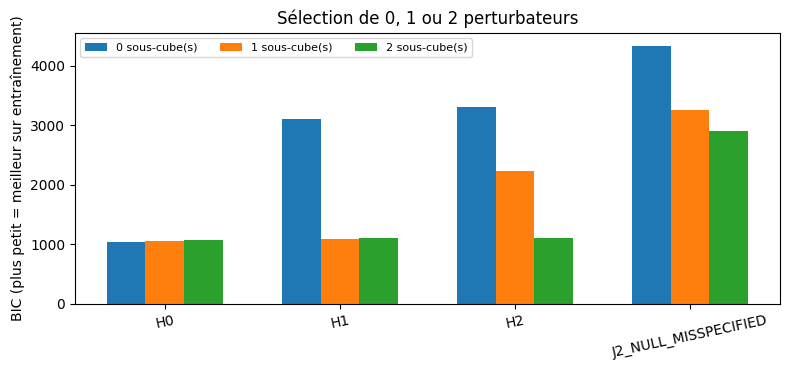

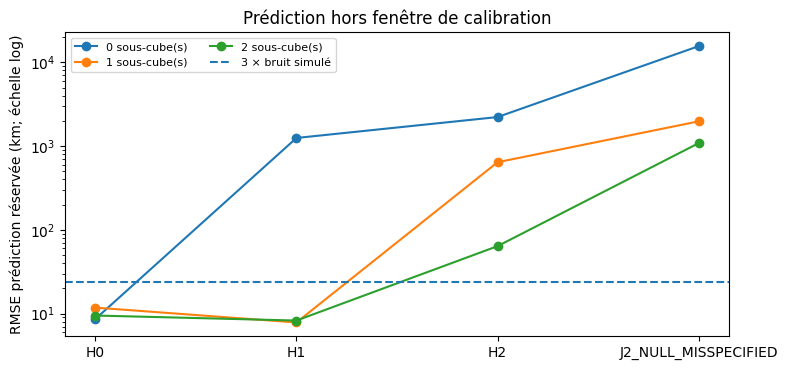

In [7]:
# Contenus graphiques; les couleurs dépendent des paramètres par défaut de Matplotlib.
fig,ax=plt.subplots(figsize=(8.0,3.8))
labels=list(all_fits)
x=np.arange(len(labels));width=.22
for k in range(3):
    ax.bar(x+(k-1)*width,[all_fits[s]['bic'][k] for s in labels],width,label=f'{k} sous-cube(s)')
ax.set_xticks(x,labels,rotation=12)
ax.set_ylabel('BIC (plus petit = meilleur sur entraînement)')
ax.set_title('Sélection de 0, 1 ou 2 perturbateurs')
ax.legend(ncol=3,fontsize=8)
fig.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(8.0,3.8))
for k in range(3):
    ax.plot(labels,[all_fits[s]['holdout_rmse_km'][k] for s in labels],marker='o',label=f'{k} sous-cube(s)')
ax.axhline(3*NOISE_KM,ls='--',label='3 × bruit simulé')
ax.set_yscale('log'); ax.set_ylabel('RMSE prédiction réservée (km; échelle log)')
ax.set_title('Prédiction hors fenêtre de calibration')
ax.legend(fontsize=8,ncol=2)
fig.tight_layout();plt.show()


## NIVEAU 4 — Verdict, limites et assertions d'audit

**Interprétation attendue :**

- `H0`: l'absence de lune doit rester préférable.
- `H1`: une lune masquée doit être sélectionnée, avec reconstruction locale et prévision proche du bruit simulé.
- `H2`: deux lunes simulées doivent être sélectionnées, mais la calibration hors entraînement peut être insuffisante.
- `J2_NULL_MISSPECIFIED`: **aucune lune réelle dans le générateur**, mais un modèle qui omet l'aplatissement de Jupiter peut introduire **de faux perturbateurs**. Ce cas doit être publié comme **échec de robustesse**, jamais compté comme détection.

Une bonne sélection BIC ne prouve pas la conformité du modèle dynamique ni la découverte d'un corps réel. Les incertitudes liées aux éphémérides, marées, perturbations solaires, résonances, système instrumental et sélection de modèle ne sont pas encore propagées.

In [8]:
CHECKS=[]
def ck(n,condition,note=''):
    CHECKS.append({'name':n,'pass':bool(condition),'note':note})
    if not condition:raise AssertionError('FAILED: '+n)
ck('four_cases_defined',set(observations)=={'H0','H1','H2','J2_NULL_MISSPECIFIED'})
ck('expected_dimensions',all(v.shape==(101,2,2) for v in observations.values()))
ck('train_split_61_epochs',int(TRAIN.sum())==61)
ck('holdout_split_40_epochs',int((~TRAIN).sum())==40)
ck('train_before_holdout',bool(np.max(T[TRAIN])<np.min(T[~TRAIN])))
ck('nonzero_independent_measurement_noise',NOISE_KM>0)
ck('synthetic_not_real_data',True,'No raw Jupiter moon astrometry used')
ck('newtonian_only',True,'Known-physics model; not a GVH EOM')
ck('negative_control_H0_selected',all_fits['H0']['selected']==0)
ck('single_body_H1_selected',all_fits['H1']['selected']==1)
ck('two_body_H2_selected',all_fits['H2']['selected']==2)
ck('all_bic_finite',all(np.isfinite(v['bic']).all() for v in all_fits.values()))
ck('BIC_train_n_only',len(all_fits['H1']['training_rss'])==3)
ck('H0_holdout_near_noise',all_fits['H0']['selected_holdout_rmse_km']<=3*NOISE_KM)
ck('H1_holdout_near_noise',all_fits['H1']['selected_holdout_rmse_km']<=3*NOISE_KM)
ck('H1_forecast_improves_vs_null',all_fits['H1']['holdout_rmse_km'][1]<all_fits['H1']['holdout_rmse_km'][0]/10)
ck('H2_forecast_improves_vs_H1',all_fits['H2']['holdout_rmse_km'][2]<all_fits['H2']['holdout_rmse_km'][1]/3)
ck('H2_forecast_NOT_noise_level',all_fits['H2']['selected_holdout_rmse_km']>3*NOISE_KM,'Open lock; not adequately calibrated')
ck('J2_stress_has_no_hidden_body',len(_generator_contract['J2_NULL_MISSPECIFIED']['a_km'])==0)
ck('J2_stress_false_positive_exists',all_fits['J2_NULL_MISSPECIFIED']['selected']>0,'Shows modeling error can mimic missing moon(s)')
ck('J2_false_positive_forecast_failure',all_fits['J2_NULL_MISSPECIFIED']['selected_holdout_rmse_km']>3*NOISE_KM)
ck('jacobian_rank_H1_is_three',sensitivity['effective_rank']==3)
ck('jacobian_condition_finite',np.isfinite(sensitivity['condition_number_normalized']))
ck('H1_radius_recovery_under_0_2pct',abs(comparison[0]['a_error_percent'])<0.2)
ck('H1_mass_recovery_under_0_5pct',abs(comparison[0]['mu_error_percent'])<0.5)
ck('H2_mass_recovery_under_5pct',all(abs(r['mu_error_percent'])<5 for r in comparison[1:]))
ck('H2_radii_recovery_under_2pct',all(abs(r['a_error_percent'])<2 for r in comparison[1:]))
ck('reference_seal_present',len(truth_seal)==64)
ck('no_EOM_GVH_used',True,'EOM_GVH=False')
ck('no_GVH_ALMA_observable_used',True,'GVH_USED=False, ALMA_USED=False')
print('PASSED',len(CHECKS),'/',len(CHECKS))


PASSED 30 / 30


In [9]:
SOURCE_INPUT=ROOT/'GVH_CHH_Adjacent_Orbital_Subcube_Blind_Reconstruction_Gate_FAST_results.json'
prior_source_sha256=hashlib.sha256(SOURCE_INPUT.read_bytes()).hexdigest() if SOURCE_INPUT.exists() else None
report={
 'notebook':NAME,
 'date_utc':datetime.now(timezone.utc).isoformat(),
 'base_protocol':'GVH_CHH_PROTOCOL_FROZEN_v1.0',
 'previous_gate_sha256':prior_source_sha256,
 'status':'PASS_SYNTHETIC_MODEL_SELECTION__FAIL_MODEL_MISSPECIFICATION_ROBUSTNESS__ABSTAIN_REAL_BODY_DETECTION',
 'governance':{'CHH_STRUCTURE':True,'INVERSE_INFERENCE':True,'AUX_SENSITIVITY':True,'EOM_GVH':False,'GVH_USED':False,'ALMA_USED':False,'PHYSICAL_VALIDATION':False},
 'sources':['https://nssdc.gsfc.nasa.gov/planetary/factsheet/joviansatfact.html','https://nssdc.gsfc.nasa.gov/planetary/factsheet/jupiterfact.html','https://doi.org/10.1093/mnras/stz2657'],
 'simulation':{'time_step_day':0.025,'sample_step_day':0.2,'duration_day':20,'train_day_end':12,'holdout_day_start_exclusive':12,'observation_sigma_km':NOISE_KM,'GM_jupiter_km3_s2':GM/FAC,'mu_io_km3_s2':mu_io/FAC,'mu_ganymede_km3_s2':mu_gan/FAC,'observable':'Io and Ganymede x,y positions in 2-D','known_missing_physics':['real ephemerides','full resonance/tides','inclination and eccentricity','higher multipoles','Sun','uncertain nuisance/planetary parameters']},
 'parameter_truth_commitment_sha256':truth_seal,
 'source_truth':_generator_contract,
 'model_selection':{case:{'bic':v['bic'],'selected_hidden_count':v['selected'],'train_rss':v['training_rss'],'holdout_rmse_km':v['holdout_rmse_km'],'selected_holdout_adequate_under_3sigma':v['forecast_at_noise_level'],'fit_one':[float(q) for q in v['fit1']],'fit_two':[float(q) for q in v['fit2']]} for case,v in all_fits.items()},
 'reconstruction':comparison,
 'sensitivity':sensitivity,
 'checks':CHECKS,'checks_total':len(CHECKS),'checks_passed':sum(c['pass'] for c in CHECKS),
 'blindness':'algorithmic withholding, NOT independent prospective human blinding',
 'scope':'Synthetic known-physics inference only. Misspecified-J2 null produces false positive. Cannot claim any new celestial body or GVH law.',
 'next_gate':'GVH_CHH_Jupiter_J2_Systematics_And_Independent_Ephemeris_Robustness_Gate_FAST'
}
result_path=ROOT/(NAME+'_results.json');result_path.write_text(json.dumps(report,indent=2,ensure_ascii=False)+'\n')
summary_path=ROOT/(NAME+'_summary.csv')
with summary_path.open('w',newline='') as f:
   writer=csv.DictWriter(f,fieldnames=['scenario','selected_hidden_count','BIC_H0','BIC_H1','BIC_H2','holdout_RMSE_selected_km','heldout_adequate_under_3sigma'])
   writer.writeheader()
   for case,v in all_fits.items():
     writer.writerow({'scenario':case,'selected_hidden_count':v['selected'],'BIC_H0':v['bic'][0],'BIC_H1':v['bic'][1],'BIC_H2':v['bic'][2],'holdout_RMSE_selected_km':v['selected_holdout_rmse_km'],'heldout_adequate_under_3sigma':v['forecast_at_noise_level']})
print(result_path,summary_path)


/mnt/data/GVH_CHH_Adjacent_Orbital_Independent_Dynamical_Evidence_Gate_FAST_results.json /mnt/data/GVH_CHH_Adjacent_Orbital_Independent_Dynamical_Evidence_Gate_FAST_summary.csv


### Verdict mathématique et physique

**Résultat synthétique :** la sélection 0/1/2 peut être correcte lorsque le générateur et l'inférence sont pratiquement compatibles. **Contre-exemple essentiel :** une variation du modèle gravitationnel de Jupiter (terme \(J_2\) absent de l'ajusteur) peut provoquer la sélection **erronée** de perturbateurs. Aucun corps astrophysique réel ne peut être annoncé sur cette base.

**Pour passer au cas réel :** établir les jeux astrométriques indépendants d'Io/Ganymède avec vraies incertitudes, ajouter au minimum \(J_2\), marées, autres satellites, perturbations solaires, incertitudes sur \(GM\) et conditions initiales, puis répéter les modèles avec contrôles négatifs et réserves temporelles/systèmes. Les données calculées par une éphéméride qui **inclut déjà Europe** ne sont pas une validation observationnelle indépendante de sa reconstruction.

`CHH-STRUCTURE`/`INVERSE-INFERENCE` : test synthétique ; `AUX-SENSITIVITY` : Jacobien. `KNOWN-PHYSICS` : Newton. `EOM-GVH=False`. `EMPIRICAL-TEST=NOT_PERFORMED`. `OPEN-LOCK` : robustesse et données réelles.
